### Section 4: Measures of Shape and Distribution Geometry
#### Skewness, Kurtosis, Statistical Moments & Geometric Transformations

While **central tendency** gives the center (1st moment), and **dispersion** gives the spread (2nd moment), **measures of shape** describe the geometry of the distribution:
> **"Is the distribution lopsided (Skewness)? Are extreme outlier tails heavy or light (Kurtosis)?"**

Below are clear, practical examples covering the core measures of shape and geometry, complete with mathematical formulas, notation pronunciations, and Python implementation comparisons across **Plain Python**, **NumPy**, **SciPy**, and **Matplotlib**:
1. **The Four Statistical Moments**
2. **Skewness (Symmetric, Right-Skewed, Left-Skewed)**
3. **Pearson's & Bowley's Skewness Formulas**
4. **Kurtosis: The 3 Types Deep-Dive (Mesokurtic, Leptokurtic, Platykurtic)**
5. **Excess Kurtosis & Tail-Risk / Black Swan Phenomenon**
6. **Python Implementation with Concrete Examples for Each Kurtosis Type**
7. **Fixing Skewness (Log & Power Transformations)**
8. **Summary Cheat Sheet & Decision Matrix**
---
---


### Setup


In [2]:
import statistics
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import math

# Set plot style
plt.style.use('seaborn_v0_8_white' if 'seaborn_v0_8_white' in plt.style.available else 'default')
plt.rcParams["figure.dpi"] = 100
np.random.seed(42)

print("Libraries imported successfully!")


Libraries imported successfully!


---
## 1. The Four Statistical Moments of a Distribution

Every distribution's geometry can be mathematically described by **four fundamental moments**:

| Moment | Name | Mathematical Formula | What it Describes |
| :---: | :---: | :---: | :--- |
| **1st Moment** | **Mean ($\mu$)** | $\frac{1}{n}\sum x_i$ | **Location / Center:** Center of mass of data |
| **2nd Moment** | **Variance ($\sigma^2$)** | $\frac{1}{n}\sum (x_i - \mu)^2$ | **Scale / Dispersion:** Spread around the center |
| **3rd Moment** | **Skewness ($g_1$)** | $\frac{1}{n\sigma^3}\sum (x_i - \mu)^3$ | **Asymmetry / Shape:** Left vs. Right tail stretch |
| **4th Moment** | **Kurtosis ($a_4$)** | $\frac{1}{n\sigma^4}\sum (x_i - \mu)^4$ | **Tails / Extremes:** Propensity for extreme outlier events |


---
## 2. Skewness (Asymmetry of the Distribution)

* **What it does:** Measures the degree and direction of asymmetry in a distribution.
* **Three Fundamental Shapes:**
  1. **Symmetric (Normal / Bell Curve, $\text{Skew} \approx 0$):**
     * Both tails are balanced.
     * $\mathbf{\text{Mean} \approx \text{Median} \approx \text{Mode}}$
  2. **Positively Skewed (Right-Skewed, $\text{Skew} > 0$):**
     * The long tail stretches to the **right** (positive direction).
     * High outlier values pull the mean: $\mathbf{\text{Mean} > \text{Median} > \text{Mode}}$
     * *Examples:* Household income, house prices, software bug fix times.
  3. **Negatively Skewed (Left-Skewed, $\text{Skew} < 0$):**
     * The long tail stretches to the **left** (negative direction).
     * Low outlier values pull the mean down: $\mathbf{\text{Mean} < \text{Median} < \text{Mode}}$
     * *Examples:* Age at natural death in developed nations, scores on an easy exam.


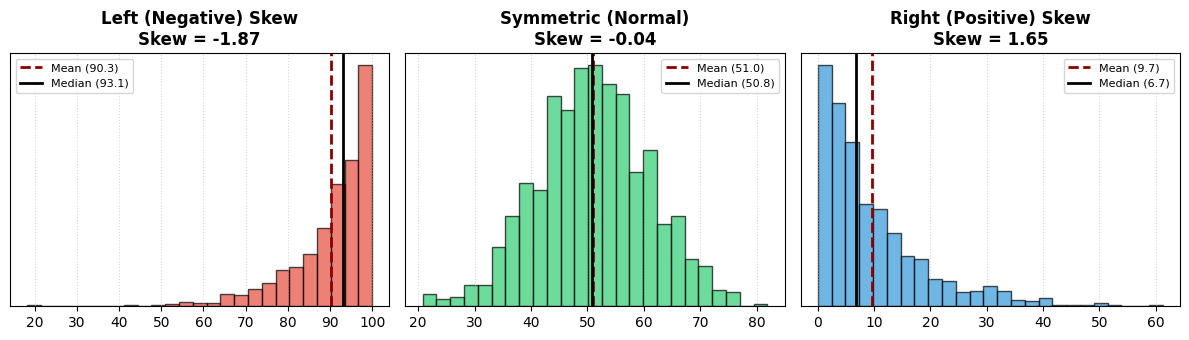

In [5]:
# 2. Skewness Visual Demonstration
np.random.seed(42)

# Generate 3 representative datasets
n = 1000
left_skewed  = 100 - np.random.exponential(scale=10, size=n)   # Negative skew
symmetric    = np.random.normal(loc=50, scale=10, size=n)       # Zero skew
right_skewed = np.random.exponential(scale=10, size=n)          # Positive skew

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=False)

datasets = [left_skewed, symmetric, right_skewed]
titles = [f"Left (Negative) Skew\nSkew = {stats.skew(left_skewed):.2f}", 
          f"Symmetric (Normal)\nSkew = {stats.skew(symmetric):.2f}", 
          f"Right (Positive) Skew\nSkew = {stats.skew(right_skewed):.2f}"]
colors = ['#e74c3c', '#2ecc71', '#3498db']

for ax, d, t, c in zip(axes, datasets, titles, colors):
    ax.hist(d, bins=25, color=c, alpha=0.7, density=True, edgecolor='black')
    
    # Mark Mean and Median
    mean_val = np.mean(d)
    med_val  = np.median(d)
    ax.axvline(mean_val, color='darkred', linestyle='--', lw=2, label=f'Mean ({mean_val:.1f})')
    ax.axvline(med_val,  color='black',   linestyle='-',  lw=2, label=f'Median ({med_val:.1f})')
    
    ax.set_title(t, fontweight='bold')
    ax.set_yticks([])
    ax.legend(fontsize=8)
    ax.grid(axis='x', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()


---
## 3. Calculating Skewness in Python

### A. Pearson's Median Skewness (Simple / Intuitive):
$$Sk_2 = \frac{3(\bar{x} - \text{Median})}{s}$$
* If $\bar{x} > \text{Median} \implies$ Positive Skew
* If $\bar{x} < \text{Median} \implies$ Negative Skew

### B. Fisher-Pearson Standardized Moment (SciPy Default):
$$g_1 = \frac{\frac{1}{n} \sum (x_i - \bar{x})^3}{s^3}$$

### C. Bowley's Quartile Skewness (Robust against Outliers):
$$Sk_B = \frac{(Q_3 - Q_2) - (Q_2 - Q_1)}{Q_3 - Q_1} = \frac{Q_3 + Q_1 - 2Q_2}{Q_3 - Q_1}$$
* Bounded strictly between $-1.0$ and $+1.0$.


In [7]:
# 3. Skewness Formulas Example: Daily Household Incomes (₹ Thousands)
incomes = [15, 18, 20, 22, 25, 28, 30, 35, 120]  # Outlier of 120 creates right skew

mean_inc = np.mean(incomes)
med_inc  = np.median(incomes)
std_inc  = np.std(incomes, ddof=1)
n = len(incomes)

# 1. Pearson's Median Skewness
pearson_skew = 3 * (mean_inc - med_inc) / std_inc

# 2. Fisher-Pearson 3rd Moment (Plain Python)
m3 = sum((x - mean_inc)**3 for x in incomes) / n
m2 = sum((x - mean_inc)**2 for x in incomes) / n
fisher_skew_python = m3 / (m2 ** 1.5)

# 3. SciPy stats.skew (bias=False for sample-unbiased)
fisher_skew_scipy = stats.skew(incomes, bias=False)

# 4. Bowley's Quartile Skewness
q1, q2, q3 = np.percentile(incomes, [25, 50, 75])
bowley_skew = (q3 + q1 - 2*q2) / (q3 - q1)

print(f"Data: {incomes}")
print(f"Mean   : ₹{mean_inc:.1f}k | Median : ₹{med_inc:.1f}k")
print("-" * 55)
print(f"Pearson's Median Skewness     : {pearson_skew:+.3f}")
print(f"Fisher-Pearson Skew (Python)  : {fisher_skew_python:+.3f}")
print(f"Fisher-Pearson Skew (SciPy)   : {fisher_skew_scipy:+.3f}")
print(f"Bowley's Quartile Skewness    : {bowley_skew:+.3f}")
print("-" * 55)
print("Conclusion: Positive value confirms Right-Skewed distribution!")


Data: [15, 18, 20, 22, 25, 28, 30, 35, 120]
Mean   : ₹34.8k | Median : ₹25.0k
-------------------------------------------------------
Pearson's Median Skewness     : +0.901
Fisher-Pearson Skew (Python)  : +2.304
Fisher-Pearson Skew (SciPy)   : +2.793
Bowley's Quartile Skewness    : +0.000
-------------------------------------------------------
Conclusion: Positive value confirms Right-Skewed distribution!


---
## 4. Kurtosis: Tail-Weight, Outlier Propensity & Extreme Event Risk

### What Kurtosis Truly Measures (Debunking the "Peakedness" Myth):
* **The Common Misconception:** Many beginner textbooks describe kurtosis simply as how "peaked" or "pointed" a curve is.
* **The Modern Statistical Reality (Westfall, 2014):** Kurtosis primarily measures **tail-heaviness and outlier propensity**!
* In simple terms, Kurtosis answers:
  > *"How frequently do extreme, unexpected outlier events occur in this distribution compared to a normal bell curve?"*

---

### Mathematical Definition & Excess Kurtosis:
$$\text{Full Kurtosis } (\beta_2) = \frac{\frac{1}{n} \sum_{i=1}^n (x_i - \bar{x})^4}{\left(\frac{1}{n} \sum_{i=1}^n (x_i - \bar{x})^2\right)^2}$$

$$\mathbf{\text{Excess Kurtosis } (\gamma_2)} = \beta_2 - 3$$

> **Why subtract 3?**  
> For any standard Gaussian Normal distribution, $\beta_2 = 3$.  
> Subtracting 3 sets the **Normal baseline to 0.0**. SciPy (`fisher=True`) and Pandas report **Excess Kurtosis**.

---

### The Three Types of Kurtosis Explained with Real-World Examples:

| Type | Greek Root | Excess Kurtosis | Tail Nature | Probability of Outliers | Real-World Everyday Examples |
| :--- | :--- | :---: | :--- | :---: | :--- |
| **1. Mesokurtic** | *Meso* = Middle | $\gamma_2 \approx 0$ (Full $\beta_2 \approx 3$) | **Moderate / Standard Tails** | **Low (Normal)**  <br>($|z| > 3$ happens only 0.27% of the time) | • Adult human heights in a population<br>• Calibrated factory bottle-filling (500ml)<br>• Standardized IQ test scores ($\mu=100, \sigma=15$) |
| **2. Leptokurtic** | *Lepto* = Slender / Fat-tailed | $\mathbf{\gamma_2 > 0}$ (Full $\beta_2 > 3$) | **Heavy, Fat, Thick Tails** <br>*(with a sharp center peak)* | **Very High (Fat-Tailed Risk)** <br>Extreme "Black Swan" events occur often! | • **Financial & Crypto Returns:** Most days have small changes near 0%, but occasional massive market crashes (-15%) or surges (+40%)<br>• **Server API Latency:** 99% of requests take 15ms, but rare database locks cause 5,000ms spikes<br>• **Earthquake Energy:** Frequent micro-tremors, but occasional massive destructive quakes |
| **3. Platykurtic** | *Platy* = Broad / Flat-topped | $\mathbf{\gamma_2 < 0}$ (Full $\beta_2 < 3$) | **Thin, Light, Short Tails** <br>*(with a flat top / plateau)* | **Virtually Zero** <br>Values stay bounded; no extreme outliers | • **Rolling a Fair 6-Sided Die:** Equal probability for {1, 2, 3, 4, 5, 6}; no outliers beyond 1 or 6<br>• **Laser-Inspected Manufacturing:** Parts deviating by >0.05mm are automatically discarded<br>• **Student Exam Arrival Times:** Controlled entry window (8:50 AM to 9:00 AM) |


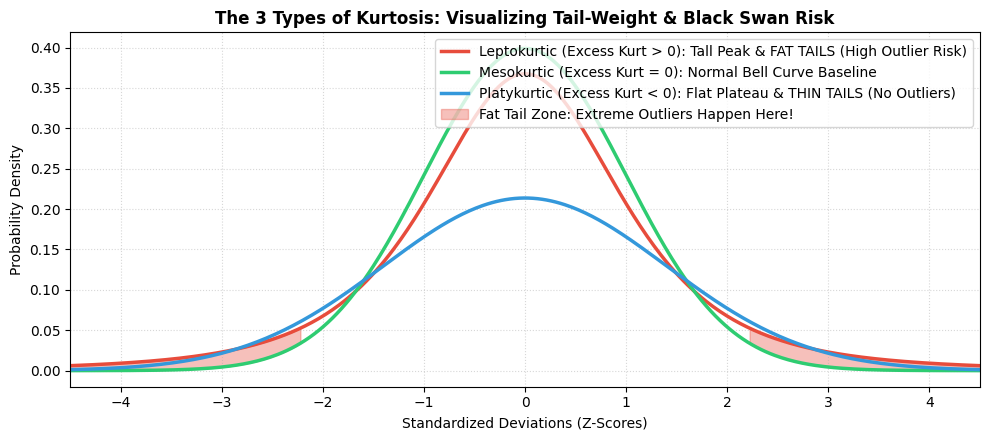

In [9]:
# 4. Kurtosis Geometry Visualization: Fat Tails vs. Thin Tails
x_vals = np.linspace(-4.5, 4.5, 400)

# 1. Leptokurtic: Student-t distribution (df=3 has heavy fat tails)
lepto_pdf = stats.t.pdf(x_vals, df=3)

# 2. Mesokurtic: Standard Normal Distribution N(0, 1)
meso_pdf = stats.norm.pdf(x_vals, 0, 1)

# 3. Platykurtic: Truncated flat curve (Uniform-like shape)
platy_pdf = stats.norm.pdf(x_vals, 0, 1.4) * 0.75  # Flatter peak, dispersed shoulders

plt.figure(figsize=(10, 4.5))
plt.plot(x_vals, lepto_pdf, color='#e74c3c', lw=2.5, label='Leptokurtic (Excess Kurt > 0): Tall Peak & FAT TAILS (High Outlier Risk)')
plt.plot(x_vals, meso_pdf,  color='#2ecc71', lw=2.5, label='Mesokurtic (Excess Kurt = 0): Normal Bell Curve Baseline')
plt.plot(x_vals, platy_pdf, color='#3498db', lw=2.5, label='Platykurtic (Excess Kurt < 0): Flat Plateau & THIN TAILS (No Outliers)')

# Highlight the Fat Tail region (where Leptokurtic curve stays higher than Normal!)
plt.fill_between(x_vals, lepto_pdf, meso_pdf, where=(x_vals > 2.2), color='#e74c3c', alpha=0.35, label='Fat Tail Zone: Extreme Outliers Happen Here!')
plt.fill_between(x_vals, lepto_pdf, meso_pdf, where=(x_vals < -2.2), color='#e74c3c', alpha=0.35)

plt.title('The 3 Types of Kurtosis: Visualizing Tail-Weight & Black Swan Risk', fontweight='bold', fontsize=12)
plt.xlabel('Standardized Deviations (Z-Scores)')
plt.ylabel('Probability Density')
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle=':', alpha=0.5)
plt.xlim(-4.5, 4.5)
plt.tight_layout()
plt.show()


---
## 5. Concrete Python Examples for Each Kurtosis Type

Below we analyze three real-world simulated datasets:
1. **Calibrated Factory Weights:** Follows Gaussian Normal distribution $\rightarrow$ **Mesokurtic**
2. **Crypto Daily Returns (%):** Clustered near 0 with massive outlier spikes $\rightarrow$ **Leptokurtic**
3. **Class Exam Arrival Minutes:** Uniformly dispersed across a fixed window $\rightarrow$ **Platykurtic**


In [11]:
# 5. Calculating Kurtosis for Mesokurtic, Leptokurtic, and Platykurtic Datasets

# Dataset 1: Factory Beverage Cans (Target 500ml) -> Mesokurtic (Normal)
weights = [500.1, 499.8, 500.2, 499.9, 500.0, 500.3, 499.7, 500.1, 499.9, 500.0]

# Dataset 2: Crypto Daily Price Moves (%) with extreme shock days -> Leptokurtic (Fat Tails)
crypto_returns = [0.2, -0.1, 0.3, 0.0, -0.2, 0.1, -0.1, 0.2, 14.5, -18.2]

# Dataset 3: Uniformly Polled Sensor Intervals (Seconds: 10 to 20) -> Platykurtic (Flat / Thin Tails)
sensor_intervals = [10.0, 11.2, 12.5, 13.8, 15.0, 16.2, 17.5, 18.8, 19.5, 20.0]

datasets = {
    "1. Factory Weights (Normal)": weights,
    "2. Crypto Returns (Volatile)": crypto_returns,
    "3. Sensor Intervals (Uniform)": sensor_intervals
}

print("=" * 80)
print(f"{'Dataset Name':<30} | {'Full Kurt (β2)':<16} | {'Excess Kurt (γ2)':<18} | {'Type Classification'}")
print("=" * 80)

for name, data in datasets.items():
    # Full Kurtosis (fisher=False)
    full_k = stats.kurtosis(data, fisher=False, bias=False)
    
    # Excess Kurtosis (fisher=True, standard in SciPy)
    excess_k = stats.kurtosis(data, fisher=True, bias=False)
    
    if excess_k > 0.5:
        k_type = "LEPTOKURTIC (Fat Tails / Outlier Heavy)"
    elif excess_k < -0.5:
        k_type = "PLATYKURTIC (Thin Tails / Flat Top)"
    else:
        k_type = "MESOKURTIC (Normal Baseline)"
        
    print(f"{name:<30} | {full_k:<16.2f} | {excess_k:<18.2f} | {k_type}")
print("=" * 80)

# Plain Python Calculation Demonstration for Crypto Returns
n = len(crypto_returns)
mean_c = sum(crypto_returns) / n
var_c  = sum((x - mean_c)**2 for x in crypto_returns) / n
m4_c   = sum((x - mean_c)**4 for x in crypto_returns) / n

python_full_k = m4_c / (var_c ** 2)
python_excess_k = python_full_k - 3.0

print(f"\nVerification with Pure Python formula for Crypto Returns:")
print(f"  Sample Mean       = {mean_c:+.2f}%")
print(f"  Full Kurtosis     = {python_full_k:.2f}")
print(f"  Excess Kurtosis   = {python_excess_k:+.2f} (Massive positive excess proves Leptokurtic!)")


Dataset Name                   | Full Kurt (β2)   | Excess Kurt (γ2)   | Type Classification
1. Factory Weights (Normal)    | 2.55             | -0.45              | MESOKURTIC (Normal Baseline)
2. Crypto Returns (Volatile)   | 7.75             | 4.75               | LEPTOKURTIC (Fat Tails / Outlier Heavy)
3. Sensor Intervals (Uniform)  | 1.64             | -1.36              | PLATYKURTIC (Thin Tails / Flat Top)

Verification with Pure Python formula for Crypto Returns:
  Sample Mean       = -0.33%
  Full Kurtosis     = 5.14
  Excess Kurtosis   = +2.14 (Massive positive excess proves Leptokurtic!)


---
## 6. Fixing Skewness: Data Transformations

* **Why fix skewness?**
  * Many predictive and machine learning algorithms (Linear Regression, Logistic Regression, Neural Networks, PCA) assume features follow a Gaussian bell curve.
* **Common Remedies for Right-Skewed Data:**
  1. **Log Transformation:** $y = \log(x)$ or $y = \log(1 + x)$ (compresses large right-hand outliers).
  2. **Square Root Transformation:** $y = \sqrt{x}$ (mild right skew).
  3. **Box-Cox Power Transformation:** Finds the mathematically optimal power parameter $\lambda$.


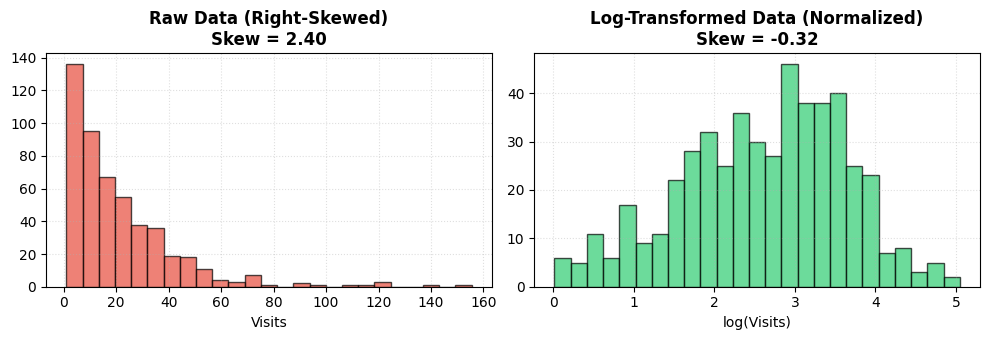

In [13]:
# 6. Fixing Right-Skewed Data using Log Transformation
# Heavily skewed positive values (e.g. Website page visits)
raw_visits = np.random.exponential(scale=20, size=500) + 1

# Log transform
log_visits = np.log(raw_visits)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

# Raw Data
ax1.hist(raw_visits, bins=25, color='#e74c3c', alpha=0.7, edgecolor='black')
ax1.set_title(f'Raw Data (Right-Skewed)\nSkew = {stats.skew(raw_visits):.2f}', fontweight='bold')
ax1.set_xlabel('Visits')
ax1.grid(True, linestyle=':', alpha=0.4)

# Log Transformed
ax2.hist(log_visits, bins=25, color='#2ecc71', alpha=0.7, edgecolor='black')
ax2.set_title(f'Log-Transformed Data (Normalized)\nSkew = {stats.skew(log_visits):.2f}', fontweight='bold')
ax2.set_xlabel('log(Visits)')
ax2.grid(True, linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()


---
## 7. Master Cheat Sheet & Decision Matrix

| Metric | Range / Threshold | Interpretation | Shape Characteristic | Action / Decision |
| :--- | :--- | :--- | :--- | :--- |
| **Skewness** | $-0.5 \le \text{Skew} \le +0.5$ | **Fairly Symmetric** | Balanced left & right tails | Mean and Standard Deviation are safe to use. |
| **Skewness** | $+0.5 < \text{Skew} \le +1.0$ | **Moderately Right-Skewed** | Right tail pulled by high values | Prefer Median / IQR; consider square-root transform. |
| **Skewness** | $\text{Skew} > +1.0$ or $\text{Skew} < -1.0$ | **Highly Skewed** | Severe tail lopsidedness | Mean is distorted! Use Log or Box-Cox transform. |
| **Excess Kurtosis** | $\text{Excess Kurt} \approx 0$ | **Mesokurtic** | Normal Gaussian bell curve | Standard Normal assumptions hold cleanly. |
| **Excess Kurtosis** | $\mathbf{\text{Excess Kurt} > 0}$ | **Leptokurtic** | **Tall peak & FAT TAILS** | High risk of extreme outliers / Black Swans. Use robust metrics (Median, MAD, Modified Z). |
| **Excess Kurtosis** | $\mathbf{\text{Excess Kurt} < 0}$ | **Platykurtic** | **Flat top & THIN TAILS** | Very few outliers; safe, predictable bounds. |
